# HW1. Решение

Ноутбук только загружает модели и пишет предсказания. Обучение и графики тем — в исходном архиве, в `task2_topics.ipynb`.

Пути задаёт первая ячейка кода. На проверке их подставляют через переменные
окружения.

In [6]:
import os

import pandas as pd

from solution_utils import (
    compute_metrics,
    compute_partition_metrics,
    init_reaction_models,
    init_topic_models,
    predict_reaction,
    predict_topic,
    read_dialogs,
    read_labels,
    save_predictions,
)

from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay


In [7]:
def default_data_path():
    # локально файл лежит в data/, у проверяющих — рядом с ноутбуком
    for path in ("data/hidden_test.jsonl", "data/hw1_train.jsonl", "hw1_train.jsonl", "hw_1/data/hw1_train.jsonl"):
        if os.path.exists(path):
            return path
    return "data/hw1_train.jsonl"

TRAIN_PATH = os.environ.get("HW1_TRAIN", "data/hw1_train.jsonl")
DATA_PATH = os.environ.get("HW1_DATA", default_data_path())
default_labels = "data/hidden_labels.jsonl" if (
    Path(DATA_PATH).resolve() == Path("data/hidden_test.jsonl").resolve()
    and Path("data/hidden_labels.jsonl").exists()
) else DATA_PATH
LABELS_PATH = os.environ.get("HW1_LABELS", default_labels)
PREDICTIONS_PATH = os.environ.get("HW1_PREDICTIONS", "predictions.csv")

dialogs = read_dialogs(DATA_PATH)
print("данные:", DATA_PATH)
print("диалогов:", len(dialogs))

данные: data/hidden_test.jsonl
диалогов: 990


## Задача 1. Реакция

Grisha_909 и Stack_909, обученные на сбалансированной выборке тоже добавлены. (Особо сильно метрики вроде не поменялись)

/home/nika/TeamSpirit_hw_1/.venv_1/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/nika/TeamSpirit_hw_1/.venv_1/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/nika/TeamSpirit_hw_1/.venv_1/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator MultinomialNB from ve

,macro_f1,accuracy,balanced_accuracy,negative_precision,negative_recall,negative_f1-score,neutral_precision,neutral_recall,neutral_f1-score,positive_precision,positive_recall,positive_f1-score
Naive Bayes,0.4191,0.4283,0.4283,0.3945,0.6121,0.4798,0.4205,0.3848,0.4019,0.5398,0.2879,0.3755
Logistic Regression,0.5374,0.5424,0.5424,0.5179,0.6121,0.5611,0.4788,0.6515,0.5520,0.7947,0.3636,0.4990
SVM,0.4926,0.5061,0.5061,0.5139,0.5606,0.5362,0.4330,0.6848,0.5305,0.8333,0.2727,0.4110
decision_2x,0.6754,0.6737,0.6737,0.6801,0.6636,0.6718,0.5645,0.8091,0.6650,0.9282,0.5485,0.6895
score_stacking_lr,0.6783,0.6788,0.6788,0.6371,0.7182,0.6752,0.6689,0.6000,0.6326,0.7360,0.7182,0.7270
Grisha_909,0.6754,0.6747,0.6747,0.6139,0.7758,0.6854,0.6380,0.6515,0.6447,0.8347,0.5970,0.6961
Stack_909,0.6755,0.6747,0.6747,0.6354,0.6970,0.6647,0.6531,0.6788,0.6657,0.7509,0.6485,0.6959


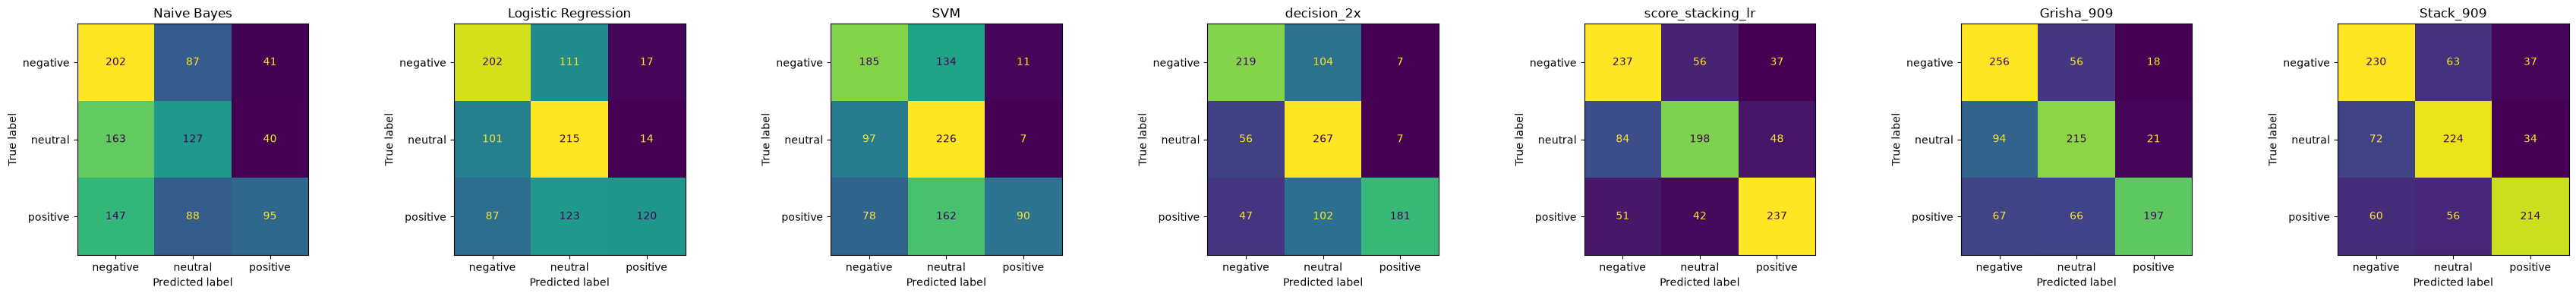

In [8]:
reaction_models = init_reaction_models(TRAIN_PATH)
reaction_labels = read_labels(LABELS_PATH, "reaction") if LABELS_PATH else {}

reaction_predictions, reaction_metrics = {}, {}
for name, model in reaction_models.items():
    reaction_predictions[name] = predict_reaction(model, dialogs)
    if reaction_labels:
        reaction_metrics[name] = compute_metrics(dialogs, reaction_predictions[name], reaction_labels)

if reaction_metrics:
    reaction_table = pd.DataFrame(reaction_metrics).T
    display(reaction_table.round(4))
    reaction_table.to_csv(Path(PREDICTIONS_PATH).with_name("reaction_metrics.csv"))
    matched = [i for i, dialog in enumerate(dialogs) if dialog["dialog_id"] in reaction_labels]
    truth = [reaction_labels[dialogs[i]["dialog_id"]] for i in matched]
    fig, axes = plt.subplots(1, len(reaction_predictions), figsize=(5 * len(reaction_predictions), 4), squeeze=False)
    for ax, (name, values) in zip(axes[0], reaction_predictions.items()):
        ConfusionMatrixDisplay.from_predictions(
            truth, [values[i] for i in matched], ax=ax,
            labels=["negative", "neutral", "positive"], colorbar=False,
        )
        ax.set_title(name)
    plt.tight_layout()
    plt.show()

## Задача 2. Темы

Модели из `artifacts/` ставят одно из 16 имён тем. На скрытом тесте
сравнивают разбиения, не сами названия.

In [9]:
topic_models = init_topic_models(TRAIN_PATH)
topic_labels = read_labels(LABELS_PATH, "topic") if LABELS_PATH else {}

topic_predictions, topic_metrics = {}, {}
for name, model in topic_models.items():
    topic_predictions[name] = predict_topic(model, dialogs)
    if topic_labels:
        topic_metrics[name] = compute_partition_metrics(dialogs, topic_predictions[name], topic_labels)

if topic_metrics:
    topic_table = pd.DataFrame(topic_metrics).T
    display(topic_table.round(4))
    topic_table.to_csv(Path(PREDICTIONS_PATH).with_name("topic_metrics.csv"))

,ARI,NMI,homogeneity,completeness,v_measure,purity
dummy,0.0000,0.0000,0.0000,1.0000,0.0000,0.4040
bow_nb,0.2064,0.3466,0.3529,0.3405,0.3466,0.5152
tfidf_logreg,0.1423,0.2665,0.2692,0.2638,0.2665,0.4848
tfidf_linearsvc,0.1697,0.2784,0.2889,0.2687,0.2784,0.4889
tfidf_bigram_sublinear,0.2017,0.2932,0.3026,0.2845,0.2932,0.4980


## Ответы всех моделей

In [10]:
save_predictions(
    PREDICTIONS_PATH,
    dialogs,
    {"reaction": reaction_predictions, "topic": topic_predictions},
)
print("строк в файле ответов:", len(dialogs) * (len(reaction_predictions) + len(topic_predictions)))

строк в файле ответов: 11880
